# Tugas Mandiri P6: Data Cleaning dan Exploratory Data Analysis
## Deteksi anomali panas MODIS di Indonesia, November–Desember 2000

**Mata kuliah:** Data Mining  
**Dataset:** `modis_2000_Indonesia.csv` (salinan dari dataset pengguna `modis_2000_Indonesia(1).csv`)  
**Unit pengamatan:** satu baris = satu **rekaman deteksi piksel anomali panas**, **bukan** satu kebakaran terkonfirmasi.

### Ringkasan hasil
- Data mentah: **691 baris × 15 kolom**, 1 November–31 Desember 2000.
- Tidak ditemukan nilai kosong, duplikasi baris identik, atau pelanggaran rentang pada pemeriksaan dasar.
- **322** rekaman pada November dan **369** pada Desember; angka ini tidak mengukur jumlah kebakaran sesungguhnya.
- **594 (86,0%)** masuk kategori *dugaan kebakaran vegetasi* (`type=0`).
- Median **FRP 12,4 MW**; terdapat **62 (9,0%)** rekaman di atas batas atas IQR. Nilai ekstrem tidak otomatis keliru.
- `brightness` dan `frp` berkorelasi positif (**Pearson r ≈ 0,679**), dengan keterbatasan interpretasi.

> **Batasan:** data hanya mencakup dua bulan pada 2000. Tidak tersedia data cakupan pengamatan, tutupan awan, luas terbakar, atau verifikasi lapangan. Kesimpulan dibatasi pada **rekaman dalam CSV ini**.

## 1. Lima pertanyaan analisis (dirumuskan sebelum visualisasi)

1. **Temporal:** Bagaimana jumlah rekaman deteksi berubah antarhari dan antara November dan Desember 2000?
2. **Kategorikal:** Bagaimana komposisi jenis sumber panas (`type`) serta distribusi deteksi siang dan malam?
3. **Spasial:** Di koordinat dan pita bujur mana rekaman deteksi terkonsentrasi?
4. **Distribusi numerik:** Bagaimana sebaran FRP dan seberapa banyak nilai ekstrem berdasarkan kaidah IQR?
5. **Hubungan antarkolom:** Seberapa kuat hubungan `brightness` dan `frp`, dan apakah tetap tampak setelah nilai FRP teratas dikeluarkan sebagai uji sensitivitas?

Setiap pertanyaan akan dijawab dengan **statistik + grafik + Observation, Interpretation, Insight**.

## 2. Setup dan pemuatan data

Di **Google Colab**, unggah `modis_2000_Indonesia.csv` ke panel **Files** (atau unggah versi bernama `modis_2000_Indonesia(1).csv`), lalu jalankan sel berurutan. Notebook akan mendeteksi kedua nama file.

**Nama dan satuan kolom:** `latitude`/`longitude` (derajat), `brightness`/`bright_t31` (Kelvin), `frp` (MW), `confidence` (skor 0–100), `scan`/`track` (km), `acq_date` (tanggal), `acq_time` (HHMM UTC), `type`, `daynight`, serta metadata satelit.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .18})

# Pilih satu CSV lokal secara eksplisit jika ada; cadangan mendukung nama lama.
search_dirs = [Path('.'), Path('/mnt/data')]
file_candidates = [folder / file_name for folder in search_dirs
                   for file_name in ['modis_2000_Indonesia.csv', 'modis_2000_Indonesia(1).csv']
                   if (folder / file_name).is_file()]
if not file_candidates:
    raise FileNotFoundError('Unggah file modis_2000_Indonesia.csv ke Files di Colab terlebih dahulu.')
csv_path = file_candidates[0]
df_raw = pd.read_csv(csv_path)
print('File:', csv_path)
print('Ukuran dataset mentah:', df_raw.shape)
display(df_raw.head(5))

File: modis_2000_Indonesia.csv
Ukuran dataset mentah: (691, 15)


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,-3.0334,133.0733,317.4,1.0,1.0,2000-11-01,151,Terra,MODIS,63,6.2,300.9,8.2,D,0
1,1.2473,109.6869,318.1,1.0,1.0,2000-11-01,328,Terra,MODIS,59,6.2,294.9,9.7,D,0
2,1.3812,100.1306,313.9,3.4,1.7,2000-11-01,329,Terra,MODIS,45,6.2,277.1,50.3,D,0
3,0.8381,101.5897,346.1,2.5,1.5,2000-11-01,329,Terra,MODIS,94,6.2,293.5,186.0,D,0
4,0.8349,101.6121,335.3,2.5,1.5,2000-11-01,329,Terra,MODIS,88,6.2,294.2,115.5,D,0


## 3. Bagian A — Pemeriksaan Data Cleaning

Pemeriksaan dilakukan **sebelum** transformasi: ukuran, jenis data, nilai kosong, baris duplikat identik, kolom konstan, dan nilai tidak wajar. Tidak adanya *missing values* bukan berarti data otomatis sempurna.

In [2]:
print('TIPE DATA PER KOLOM')
display(df_raw.dtypes.astype(str).to_frame('tipe'))
print('NILAI KOSONG')
display(df_raw.isna().sum().to_frame('jumlah_kosong'))
print('Baris duplikat identik:', int(df_raw.duplicated().sum()))
print('Jumlah nilai unik per kolom:')
display(df_raw.nunique().to_frame('jumlah_unik'))
print('Jumlah kolom numerik:', len(df_raw.select_dtypes(include='number').columns))
print('Jumlah kolom non-numerik:', len(df_raw.select_dtypes(exclude='number').columns))

TIPE DATA PER KOLOM


,tipe
latitude,float64
longitude,float64
brightness,float64
scan,float64
track,float64
acq_date,object
acq_time,int64
satellite,object
instrument,object
confidence,int64


NILAI KOSONG


,jumlah_kosong
latitude,0
longitude,0
brightness,0
scan,0
track,0
acq_date,0
acq_time,0
satellite,0
instrument,0
confidence,0


Baris duplikat identik: 0
Jumlah nilai unik per kolom:


,jumlah_unik
latitude,676
longitude,685
brightness,300
scan,30
track,11
acq_date,59
acq_time,154
satellite,1
instrument,1
confidence,88


Jumlah kolom numerik: 11
Jumlah kolom non-numerik: 4


### Validasi nilai janggal dan keputusan pembersihan

Rentang yang dicek: lintang [-90, 90], bujur [-180, 180], `confidence` [0, 100], FRP ≥ 0, ukuran piksel (`scan`,`track`) > 0, kode `daynight` D/N, `type` 0/1/2/3, tanggal dan format jam UTC valid. Nilai FRP tinggi **tidak** dianggap kesalahan tanpa bukti tambahan.

In [3]:
# Periksa tanggal dan jam tanpa mengubah kolom sumber.
dates_check = pd.to_datetime(df_raw['acq_date'], errors='coerce')
time_hhmm_check = df_raw['acq_time'].astype('string').str.zfill(4)
hours_check = pd.to_numeric(time_hhmm_check.str[:2], errors='coerce')
minutes_check = pd.to_numeric(time_hhmm_check.str[2:], errors='coerce')
checks = {
    'Tanggal tidak valid': dates_check.isna().sum(),
    'Lintang di luar [-90, 90]': (~df_raw['latitude'].between(-90, 90)).sum(),
    'Bujur di luar [-180, 180]': (~df_raw['longitude'].between(-180, 180)).sum(),
    'Confidence di luar [0, 100]': (~df_raw['confidence'].between(0, 100)).sum(),
    'Jam UTC tidak valid': (~hours_check.between(0, 23)).sum(),
    'Menit UTC tidak valid': (~minutes_check.between(0, 59)).sum(),
    'FRP negatif': (df_raw['frp'] < 0).sum(),
    'Scan/track tidak positif': ((df_raw['scan'] <= 0) | (df_raw['track'] <= 0)).sum(),
    'Daynight tidak dikenali': (~df_raw['daynight'].isin(['D', 'N'])).sum(),
    'Type tidak dikenali': (~df_raw['type'].isin([0, 1, 2, 3])).sum(),
}
display(pd.Series(checks, name='jumlah_baris_bermasalah').to_frame())
print('Total temuan pemeriksaan rentang (jumlah cek):', int(sum(checks.values())))

,jumlah_baris_bermasalah
Tanggal tidak valid,0
"Lintang di luar [-90, 90]",0
"Bujur di luar [-180, 180]",0
"Confidence di luar [0, 100]",0
Jam UTC tidak valid,0
Menit UTC tidak valid,0
FRP negatif,0
Scan/track tidak positif,0
Daynight tidak dikenali,0
Type tidak dikenali,0


Total temuan pemeriksaan rentang (jumlah cek): 0


### Tindakan cleaning dan alasannya

| Tindakan | Alasan | Keputusan |
|---|---|---|
| `acq_date` → `datetime` | Memastikan tanggal valid dan siap agregasi harian/bulanan | Transformasi format, tanpa mengubah nilai tanggal |
| `acq_time` → teks 4 digit HHMM | Kolom awal numerik menghilangkan nol di depan (`0151` dibaca `151`) | Buat kolom `acq_hhmm` dan jam/menit UTC |
| `type` dan `daynight` → label kategori | Hasil analisis lebih mudah ditafsirkan | Buat `type_label` dan `daynight_label` |
| Turunkan `month`, `acq_datetime_utc` | Memudahkan analisis temporal | Tambah variabel turunan |
| Missing values & duplikasi | Pemeriksaan menunjukkan 0 | **Tidak** dilakukan imputasi atau penghapusan baris |
| FRP ekstrem | Dapat merupakan pengamatan nyata | **Dipertahankan**, diberi penanda outlier untuk analisis |
| Metadata konstan | `satellite`, `instrument`, `version` seluruhnya tetap | **Dipertahankan** sebagai dokumentasi sumber |

**Penting:** Data cleaning tidak harus menghapus baris. Menghapus nilai valid supaya terlihat "dibersihkan" justru merusak analisis.

In [4]:
df = df_raw.copy(deep=True)
df['acq_date'] = pd.to_datetime(df['acq_date'], errors='coerce')
df['acq_hhmm'] = df['acq_time'].astype('string').str.zfill(4)
df['hour_utc'] = df['acq_hhmm'].str[:2].astype(int)
df['minute_utc'] = df['acq_hhmm'].str[2:].astype(int)
df['acq_datetime_utc'] = pd.to_datetime(df['acq_date'].dt.strftime('%Y-%m-%d') + ' ' + df['acq_hhmm'].str[:2] + ':' + df['acq_hhmm'].str[2:], errors='coerce')
df['month'] = df['acq_date'].dt.to_period('M').astype(str)
df['type_label'] = df['type'].map({0: 'Dugaan kebakaran vegetasi', 1: 'Gunung berapi aktif', 2: 'Sumber panas statis lain', 3: 'Lepas pantai'})
df['daynight_label'] = df['daynight'].map({'D': 'Siang', 'N': 'Malam'})
assert len(df) == len(df_raw), 'Jumlah baris berubah tanpa alasan!'
assert df['acq_datetime_utc'].notna().all(), 'Masih ada waktu invalid.'
assert df[['type_label','daynight_label']].notna().all().all(), 'Ada kategori tidak dikenali.'
print('Sebelum cleaning:', df_raw.shape)
print('Sesudah cleaning:', df.shape)
print('Baris dihapus:', len(df_raw)-len(df))
print('Kolom turunan:', [c for c in df.columns if c not in df_raw.columns])
print('Rentang tanggal:', df['acq_date'].min().date(), 'hingga', df['acq_date'].max().date())
print('Tanggal dengan >=1 rekaman:', df['acq_date'].nunique())
display(df[['acq_date','acq_time','acq_hhmm','acq_datetime_utc','month','type','type_label','daynight_label']].head(5))

Sebelum cleaning: (691, 15)
Sesudah cleaning: (691, 22)
Baris dihapus: 0
Kolom turunan: ['acq_hhmm', 'hour_utc', 'minute_utc', 'acq_datetime_utc', 'month', 'type_label', 'daynight_label']
Rentang tanggal: 2000-11-01 hingga 2000-12-31
Tanggal dengan >=1 rekaman: 59


,acq_date,acq_time,acq_hhmm,acq_datetime_utc,month,type,type_label,daynight_label
0,2000-11-01,151,0151,2000-11-01 01:51:00,2000-11,0,Dugaan kebakaran vegetasi,Siang
1,2000-11-01,328,0328,2000-11-01 03:28:00,2000-11,0,Dugaan kebakaran vegetasi,Siang
2,2000-11-01,329,0329,2000-11-01 03:29:00,2000-11,0,Dugaan kebakaran vegetasi,Siang
3,2000-11-01,329,0329,2000-11-01 03:29:00,2000-11,0,Dugaan kebakaran vegetasi,Siang
4,2000-11-01,329,0329,2000-11-01 03:29:00,2000-11,0,Dugaan kebakaran vegetasi,Siang


## 4. Bagian B — Statistik deskriptif awal

Statistik ini membantu memahami skala, sebaran, dan kemencengan data sebelum menjawab lima pertanyaan. `FRP` memakai MW, sementara `brightness` memakai Kelvin.

In [5]:
numeric_vars = ['brightness', 'bright_t31', 'frp', 'confidence', 'scan', 'track']
display(df[numeric_vars].describe(percentiles=[.25,.50,.75,.90,.95,.99]).T.round(2))
display(df['type_label'].value_counts().to_frame('jumlah').assign(persentase=lambda x:(100*x['jumlah']/len(df)).round(1)))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
brightness,691.0,317.41,10.51,300.2,311.2,315.8,321.70,329.6,335.05,353.08,420.9
bright_t31,691.0,291.17,7.04,267.0,287.6,291.7,296.10,299.1,301.00,305.85,311.1
frp,691.0,20.10,24.43,2.2,8.2,12.4,22.45,40.7,56.10,106.97,410.1
confidence,691.0,55.16,24.30,0.0,41.0,58.0,71.50,85.0,94.00,100.00,100.0
scan,691.0,1.46,0.62,1.0,1.0,1.2,1.70,2.4,2.80,3.41,4.5
track,691.0,1.17,0.21,1.0,1.0,1.1,1.30,1.5,1.60,1.71,2.0


,jumlah,persentase
type_label,,
Dugaan kebakaran vegetasi,594,86.0
Sumber panas statis lain,85,12.3
Gunung berapi aktif,12,1.7


## Pertanyaan 1 — Bagaimana jumlah deteksi berubah menurut waktu?

Jumlah per bulan:


,rekaman
month,
2000-11,322
2000-12,369


Tanggal dengan rekaman terbanyak: 2000-12-06 - 50 rekaman
Tanggal tanpa rekaman di file: 2000-11-26, 2000-12-22


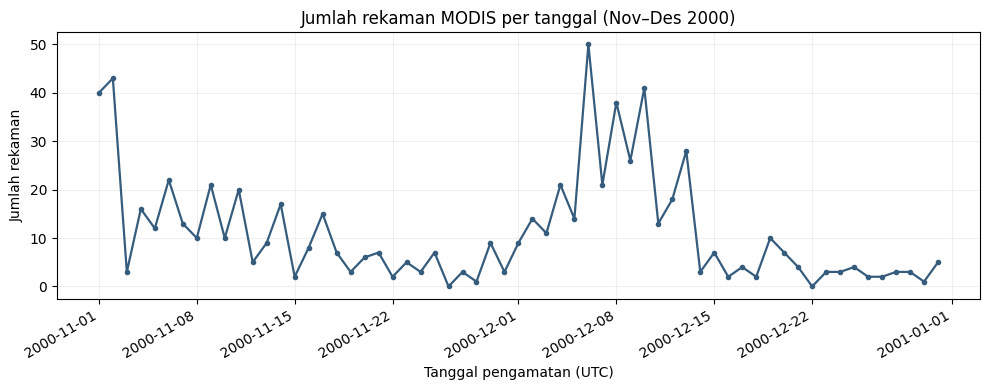

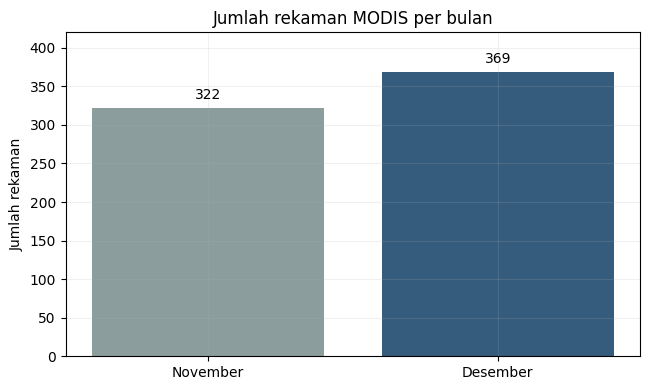

In [6]:
daily_counts = df.groupby('acq_date').size().asfreq('D', fill_value=0)
monthly_counts = df.groupby('month').size().sort_index()
print('Jumlah per bulan:')
display(monthly_counts.to_frame('rekaman'))
print('Tanggal dengan rekaman terbanyak:', daily_counts.idxmax().date(), '-', int(daily_counts.max()), 'rekaman')
print('Tanggal tanpa rekaman di file:', ', '.join(d.strftime('%Y-%m-%d') for d in daily_counts.index[daily_counts.eq(0)]))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily_counts.index, daily_counts.values, linewidth=1.6, marker='o', markersize=3, color='#355C7D')
ax.set(title='Jumlah rekaman MODIS per tanggal (Nov–Des 2000)', xlabel='Tanggal pengamatan (UTC)', ylabel='Jumlah rekaman')
fig.autofmt_xdate(); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6.6, 4))
bars = ax.bar(['November','Desember'], monthly_counts.values, color=['#8C9D9E','#355C7D'])
ax.bar_label(bars, padding=4)
ax.set(title='Jumlah rekaman MODIS per bulan', ylabel='Jumlah rekaman', ylim=(0,420))
plt.tight_layout(); plt.show()

**Observation:** November memiliki **322** rekaman dan Desember **369** rekaman (**+47; +14,6%** relatif terhadap November). Hari tertinggi adalah **6 Desember 2000** dengan **50** rekaman. Tidak ada rekaman pada **26 November** dan **22 Desember** dalam file.

**Interpretation:** Lebih banyak **baris deteksi** tercatat pada Desember, dengan lonjakan harian pada awal Desember. Periode tanpa baris **tidak membuktikan** tidak ada kebakaran.

**Insight:** Untuk membandingkan kejadian kebakaran antarperiode, perlu data cakupan lintasan satelit, awan, dan metode agregasi per kejadian. **Dua bulan ini tidak cukup** untuk menyimpulkan tren kebakaran sepanjang 2000.

## Pertanyaan 2 — Bagaimana komposisi kategori sumber panas dan siang/malam?

Distribusi tipe:


,rekaman,persentase
type_label,,
Dugaan kebakaran vegetasi,594,86.0
Sumber panas statis lain,85,12.3
Gunung berapi aktif,12,1.7


Siang/malam:


,rekaman,persentase
daynight_label,,
Siang,564,81.6
Malam,127,18.4


Tabulasi silang tipe × siang/malam:


daynight_label,Malam,Siang,All
type_label,,,
Dugaan kebakaran vegetasi,92,502,594
Gunung berapi aktif,6,6,12
Sumber panas statis lain,29,56,85
All,127,564,691


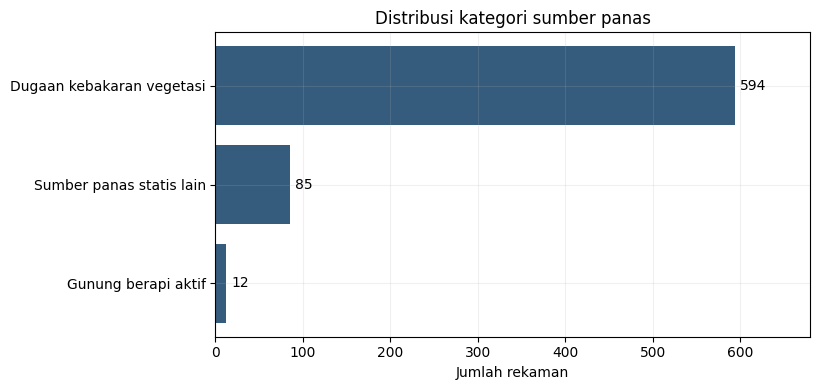

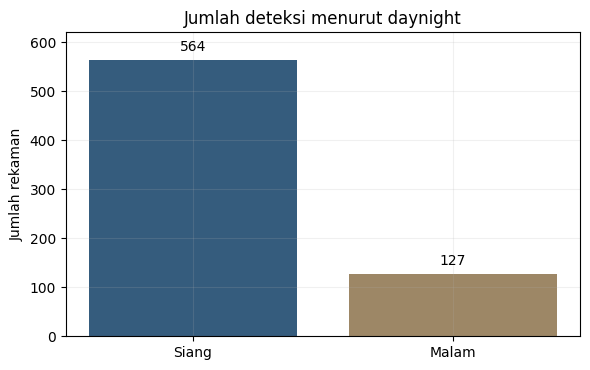

In [7]:
type_counts = df['type_label'].value_counts()
day_counts = df['daynight_label'].value_counts()
print('Distribusi tipe:')
display(pd.DataFrame({'rekaman':type_counts, 'persentase':(100*type_counts/len(df)).round(1)}))
print('Siang/malam:')
display(pd.DataFrame({'rekaman':day_counts, 'persentase':(100*day_counts/len(df)).round(1)}))
print('Tabulasi silang tipe × siang/malam:')
display(pd.crosstab(df['type_label'], df['daynight_label'], margins=True))
fig, ax = plt.subplots(figsize=(8.3, 4))
series = type_counts.sort_values()
bars = ax.barh(series.index, series.values, color='#355C7D')
ax.bar_label(bars, padding=4)
ax.set(title='Distribusi kategori sumber panas', xlabel='Jumlah rekaman', xlim=(0,680))
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(day_counts.index, day_counts.values, color=['#355C7D','#9D8766'])
ax.bar_label(bars, padding=4)
ax.set(title='Jumlah deteksi menurut daynight', ylabel='Jumlah rekaman', ylim=(0,620))
plt.tight_layout(); plt.show()

**Observation:** Dari **691** baris, **594 (86,0%)** berlabel dugaan kebakaran vegetasi, **85 (12,3%)** sumber panas statis lain, dan **12 (1,7%)** gunung berapi aktif. Terdapat **564 (81,6%)** rekaman siang dan **127 (18,4%)** malam.

**Interpretation:** Kategori dugaan kebakaran vegetasi mendominasi isi file, dan jumlah deteksi siang lebih banyak. Akan tetapi, label `type=0` merupakan **dugaan algoritmik**, sedangkan `daynight` menggambarkan kondisi pengamatan satelit.

**Insight:** Jika tujuan lanjutannya mempelajari dugaan kebakaran vegetasi, analisis sebaiknya memfilter `type=0` terlebih dahulu; komposisi siang/malam **tidak cukup** untuk menyatakan kebakaran lebih sering terjadi saat siang.

## Pertanyaan 3 — Bagaimana persebaran lokasi deteksi?

Rentang lintang: -10.2686 sampai 5.2227
Rentang bujur: 96.3762 sampai 140.9436


,rekaman,persentase (%)
longitude_band,,
90–105°BT,270,39.1
105–120°BT,168,24.3
120–135°BT,222,32.1
135–145°BT,31,4.5


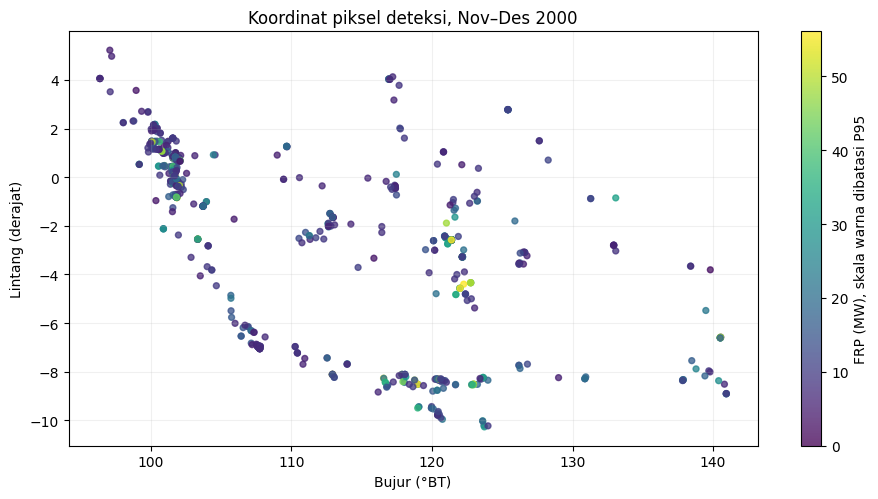

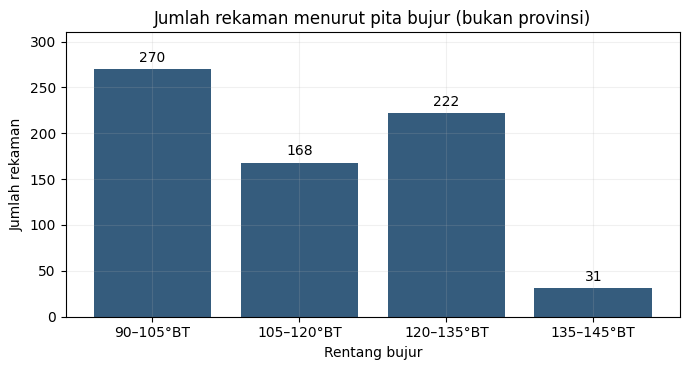

In [8]:
print('Rentang lintang:', round(df['latitude'].min(),4), 'sampai', round(df['latitude'].max(),4))
print('Rentang bujur:', round(df['longitude'].min(),4), 'sampai', round(df['longitude'].max(),4))
# Pita bujur hanya alat ringkasan, bukan batas pulau/provinsi.
longitude_bins = [90,105,120,135,145]
longitude_labels = ['90–105°BT','105–120°BT','120–135°BT','135–145°BT']
df['longitude_band'] = pd.cut(df['longitude'], longitude_bins, labels=longitude_labels)
band_counts = df['longitude_band'].value_counts().reindex(longitude_labels)
display(pd.DataFrame({'rekaman': band_counts, 'persentase (%)': (100*band_counts/len(df)).round(1)}))
fig, ax = plt.subplots(figsize=(9.5,5.1))
sc = ax.scatter(df['longitude'], df['latitude'], c=df['frp'], cmap='viridis', vmin=0, vmax=df['frp'].quantile(.95), s=18, alpha=.76)
ax.set(title='Koordinat piksel deteksi, Nov–Des 2000', xlabel='Bujur (°BT)', ylabel='Lintang (derajat)')
fig.colorbar(sc, ax=ax, label='FRP (MW), skala warna dibatasi P95')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7,3.8))
bars = ax.bar(band_counts.index, band_counts.values, color='#355C7D')
ax.bar_label(bars, padding=3)
ax.set(title='Jumlah rekaman menurut pita bujur (bukan provinsi)', xlabel='Rentang bujur', ylabel='Jumlah rekaman', ylim=(0,310))
plt.tight_layout(); plt.show()

**Observation:** Koordinat berada pada lintang **-10,2686° sampai 5,2227°** dan bujur **96,3762° sampai 140,9436°**. Pita bujur **90–105°BT** mencatat **270 rekaman (39,1%)**, terbanyak dari empat pita yang digunakan.

**Interpretation:** Deteksi tidak tersebar merata pada sumbu bujur. Pita bujur hanyalah pembagian numerik buatan analisis, **bukan** wilayah administratif maupun perhitungan kepadatan per luas wilayah.

**Insight:** Analisis provinsi/pulau memerlukan peta batas administratif dan *spatial join*. Titik yang berdekatan atau muncul berulang belum tentu kebakaran terpisah; perlu pengelompokan spasial-temporal.

## Pertanyaan 4 — Bagaimana sebaran FRP dan nilai ekstrem?

FRP (MW) mean=20.10; median=12.40; Q1=8.20; Q3=22.45; maksimum=410.1
Ambang IQR atas: 43.825 MW. Di atas ambang: 62 rekaman (9.0%).
Lima rekaman FRP terbesar:


,acq_date,latitude,longitude,frp,brightness,confidence,type_label
412,2000-12-06,0.6831,102.0711,410.1,420.9,100,Dugaan kebakaran vegetasi
3,2000-11-01,0.8381,101.5897,186.0,346.1,94,Dugaan kebakaran vegetasi
395,2000-12-06,-2.5797,121.3746,129.7,360.7,100,Sumber panas statis lain
659,2000-12-20,-8.1106,112.9260,124.6,331.4,0,Gunung berapi aktif
4,2000-11-01,0.8349,101.6121,115.5,335.3,88,Dugaan kebakaran vegetasi


FRP per tipe sumber panas:


,count,median,mean,max
type_label,,,,
Dugaan kebakaran vegetasi,594,11.55,18.62,410.1
Gunung berapi aktif,12,12.15,27.15,124.6
Sumber panas statis lain,85,19.90,29.45,129.7


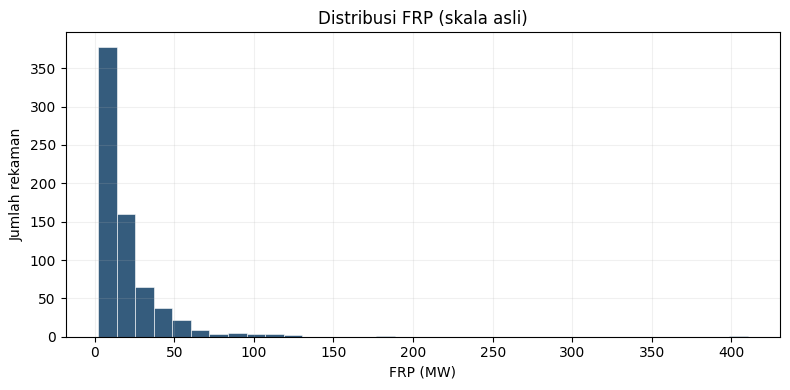

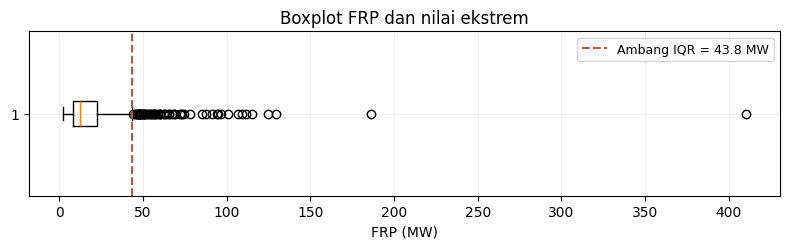

In [9]:
q1, q3 = df['frp'].quantile([.25,.75])
iqr = q3-q1
upper = q3+1.5*iqr
outlier_mask = df['frp'] > upper
print(f'FRP (MW) mean={df.frp.mean():.2f}; median={df.frp.median():.2f}; Q1={q1:.2f}; Q3={q3:.2f}; maksimum={df.frp.max():.1f}')
print(f'Ambang IQR atas: {upper:.3f} MW. Di atas ambang: {int(outlier_mask.sum())} rekaman ({outlier_mask.mean():.1%}).')
print('Lima rekaman FRP terbesar:')
display(df.nlargest(5, 'frp')[['acq_date','latitude','longitude','frp','brightness','confidence','type_label']])
print('FRP per tipe sumber panas:')
display(df.groupby('type_label')['frp'].agg(['count','median','mean','max']).round(2))
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(df['frp'], bins=35, color='#355C7D', edgecolor='white', linewidth=.4)
ax.set(title='Distribusi FRP (skala asli)', xlabel='FRP (MW)', ylabel='Jumlah rekaman')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8,2.6))
ax.boxplot(df['frp'], vert=False)
ax.axvline(upper, color='#B45A48', linestyle='--', label=f'Ambang IQR = {upper:.1f} MW')
ax.legend(loc='upper right', fontsize=9)
ax.set(title='Boxplot FRP dan nilai ekstrem', xlabel='FRP (MW)')
plt.tight_layout(); plt.show()

**Observation:** FRP rata-rata **20,10 MW** lebih tinggi daripada median **12,4 MW**. Maksimum **410,1 MW**. Dengan metode Tukey (Q3 + 1,5×IQR), terdapat **62 (9,0%)** baris di atas ambang **43,825 MW**.

**Interpretation:** Distribusi FRP menceng ke kanan (*right-skewed*): sebagian besar deteksi bernilai rendah–sedang, dengan sedikit nilai sangat tinggi. **Outlier statistik bukan bukti nilai salah.**

**Insight:** Untuk perbandingan tipikal, median dan kuantil lebih representatif daripada hanya rata-rata; FRP ekstrem perlu dianalisis, **bukan dihapus otomatis**. Uji sensitivitas membantu mengetahui pengaruh ekor distribusi.

## Pertanyaan 5 — Bagaimana hubungan brightness dan FRP?

,brightness,bright_t31,frp,confidence,scan,track
brightness,1.000,0.486,0.679,0.388,-0.130,-0.123
bright_t31,0.486,1.000,0.048,-0.040,-0.173,-0.177
frp,0.679,0.048,1.000,0.275,0.388,0.389
confidence,0.388,-0.040,0.275,1.000,-0.189,-0.190
scan,-0.130,-0.173,0.388,-0.189,1.000,0.983
track,-0.123,-0.177,0.389,-0.190,0.983,1.000


Pearson brightness–FRP (semua data): r=0.679
Spearman brightness–FRP: rho=0.539
Pearson tanpa FRP di atas P99: r=0.571 (n=684)
Pearson scan–track: r=0.983


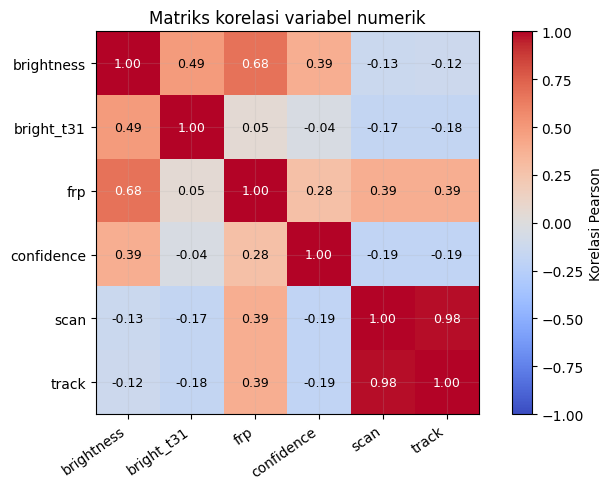

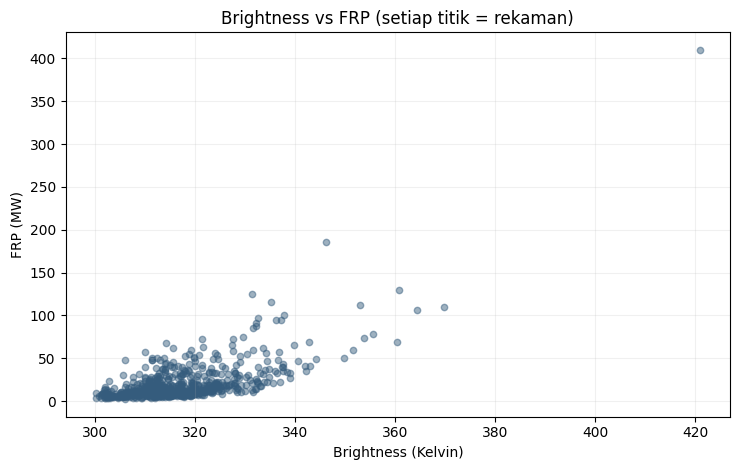

In [10]:
corr_vars = ['brightness','bright_t31','frp','confidence','scan','track']
corr = df[corr_vars].corr(method='pearson')
display(corr.round(3))
pearson_r = df['brightness'].corr(df['frp'])
spearman_rho = df['brightness'].corr(df['frp'], method='spearman')
subset_99 = df[df['frp'] <= df['frp'].quantile(.99)]
pearson_trimmed = subset_99['brightness'].corr(subset_99['frp'])
print(f'Pearson brightness–FRP (semua data): r={pearson_r:.3f}')
print(f'Spearman brightness–FRP: rho={spearman_rho:.3f}')
print(f'Pearson tanpa FRP di atas P99: r={pearson_trimmed:.3f} (n={len(subset_99)})')
print(f'Pearson scan–track: r={df.scan.corr(df.track):.3f}')
fig, ax = plt.subplots(figsize=(7.3,5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr_vars)), labels=corr_vars, rotation=35, ha='right')
ax.set_yticks(range(len(corr_vars)), labels=corr_vars)
for (r,c), val in np.ndenumerate(corr.values):
    ax.text(c,r,f'{val:.2f}',ha='center',va='center',fontsize=9,color='white' if abs(val) > .62 else 'black')
fig.colorbar(im, ax=ax, label='Korelasi Pearson')
ax.set_title('Matriks korelasi variabel numerik')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7.5,4.8))
ax.scatter(df['brightness'], df['frp'], alpha=.48, s=21, color='#355C7D')
ax.set(title='Brightness vs FRP (setiap titik = rekaman)', xlabel='Brightness (Kelvin)', ylabel='FRP (MW)')
plt.tight_layout(); plt.show()

**Observation:** Hubungan `brightness`–`frp` positif: **Pearson r ≈ 0,679** dan **Spearman ρ ≈ 0,539**. Setelah rekaman dengan FRP di atas persentil 99 dikeluarkan **untuk uji sensitivitas saja**, korelasi Pearson turun menjadi sekitar **0,571**. Korelasi `scan`–`track` sangat tinggi (**r ≈ 0,983**).

**Interpretation:** Dalam sampel ini, brightness yang lebih tinggi cenderung disertai FRP yang lebih tinggi. Kekuatan korelasi Pearson berubah saat ekor nilai ekstrem dikesampingkan, sehingga hasil sensitif terhadap pengamatan ber-FRP sangat tinggi. Ukuran piksel dan tipe sumber panas juga mungkin berkaitan dengan pengukuran.

**Insight:** Korelasi bukan kausalitas. Untuk tahap Data Mining berikutnya, cek analisis berdasarkan `type`, ukuran piksel, dan pengelompokan tanggal sebelum menggunakan brightness sebagai prediktor FRP.

## 5. Hipotesis dan kesimpulan

**Hipotesis kerja (H1):** Pada rekaman deteksi panas MODIS dalam dataset ini, **semakin tinggi `brightness`, cenderung semakin tinggi `frp`**.

**Dukungan deskriptif:** Pearson **r ≈ 0,679**, Spearman **ρ ≈ 0,539**, dan setelah uji sensitivitas tanpa FRP di atas P99 korelasi Pearson masih positif (**r ≈ 0,571**). Temuan ini **konsisten dengan** H1 pada sampel ini, tetapi tidak membuktikan sebab-akibat atau generalisasi ke semua kebakaran Indonesia. Tidak dilakukan uji signifikansi inferensial karena rekaman satelit dapat saling terkait secara spasial maupun temporal.

### Kesimpulan tugas

1. **Cleaning:** 691 baris dan 15 kolom mentah tervalidasi; 0 missing, 0 duplikasi identik, dan 0 pelanggaran pemeriksaan rentang. Perubahan utamanya adalah normalisasi tipe tanggal/waktu serta penambahan label kategori; **tidak ada baris dihapus**.
2. **EDA:** Deteksi terkonsentrasi pada label dugaan kebakaran vegetasi; Desember mencatat lebih banyak rekaman dibanding November; FRP condong ke kanan dengan nilai ekstrem; lokasi tersebar tidak merata menurut bujur; brightness–FRP berkorelasi positif.
3. **Batas kesimpulan:** Jumlah deteksi ≠ jumlah kejadian kebakaran. Pola siang/malam, perubahan antarbulan, atau konsentrasi koordinat belum memperhitungkan cakupan observasi, cuaca, atau pengulangan piksel.

**Rujukan:** data pengguna `modis_2000_Indonesia.csv` (metadata sumber asli file tidak dicantumkan). Definisi kolom: [NASA FIRMS MODIS Fire Hotspots](https://firms2.modaps.eosdis.nasa.gov/content/descriptions/FIRMS_MODIS_Firehotspots.html).

In [11]:
# Pemeriksaan akhir agar ringkasan konsisten dengan keluaran kode.
assert df_raw.shape == (691, 15)
assert len(df) == len(df_raw) and df_raw.isna().sum().sum() == 0
assert df_raw.duplicated().sum() == 0 and sum(checks.values()) == 0
assert monthly_counts.to_dict() == {'2000-11': 322, '2000-12': 369}
assert int(outlier_mask.sum()) == 62
assert int(band_counts.sum()) == len(df)
assert np.isclose(pearson_r, 0.679, atol=.001)
print('VALIDASI FINAL: semua pemeriksaan lulus. Notebook siap disimpan sebagai .ipynb yang sudah dijalankan.')

VALIDASI FINAL: semua pemeriksaan lulus. Notebook siap disimpan sebagai .ipynb yang sudah dijalankan.
